# Sile Main Canal (USGS): de video de dron a caudal con pyorc (LSPIV)

Aplica el flujo de trabajo de **pyorc** (LSPIV: *Large-Scale Particle Image Velocimetry*) a un
conjunto de datos **ajeno a la libreria**: el canal Sile Main Canal (Cochiti, Nuevo Mexico), del
data release del USGS *"Small Unoccupied Aircraft System Imagery and Associated Data used for
Discharge Measurement at Eight Locations Across the United States in 2019 and 2020"*
(DOI [10.5066/P9H2MM1M](https://doi.org/10.5066/P9H2MM1M)).

El video no lo grabo una camara fija en la orilla, sino un **dron en vuelo estacionario mirando
hacia abajo**. Eso simplifica mucho la georreferenciacion y a cambio obliga a compensar el
movimiento del aparato, que se hace **una sola vez** fuera del notebook.

Pasos:

1. Abrir el video estabilizado y extraer un fotograma
2. Fijar la escala con dos puntos de control sobre la lamina de agua
3. Construir la `CameraConfig` y el area de interes, y reproyectar
4. Calcular velocidades superficiales con LSPIV y filtrar las espurias
5. Muestrear la seccion transversal e integrar el caudal

## Como esta escrito este notebook

**Todo lo que depende del caso es una constante marcada `>>> AJUSTABLE <<<`, y cada una esta al
principio del bloque donde se usa**, con la explicacion de que es, de donde sale y que pasa si se
cambia. Las que vienen del propio data release del USGS llevan la marca *(obtenido del dataset)*.
El indice completo de esas constantes esta al final del notebook.

**No se ajusta ningun valor para acercarse al resultado de referencia.** Cada eleccion se toma
mirando el video, la geometria del canal o el valor por defecto de la libreria, y se justifica
sobre esa base. La referencia del dataset **no se abre hasta la Parte 7**: alli se compara una
vez, se anota donde queda el error, y el notebook termina. Si se retocara la configuracion despues
de esa comparacion, dejaria de haber validacion y solo quedaria un ajuste.

**Los datos de entrada se leen en modo solo lectura de `../USGS/`. Todo lo que este notebook genera
(figuras PNG, NetCDF, CSV y el JSON de configuracion) se escribe en `salidas/`.**

### Configuracion compartida con el notebook de STIV

Este video se procesa tambien en `analisis_USGS_SMC_stiv/SMC_STIV_pipeline.ipynb`, con otro
algoritmo. Para que la comparacion entre los dos mida el **algoritmo** y no la configuracion, todo
lo que no es propio del metodo se lee igual en los dos sitios:

| Constante | Valor comun | Donde |
|---|---|---|
| `FILA_AGUA_SUP`, `FILA_AGUA_INF` | 438 y 1463 -> escala 1.7842 mm/px | Parte 2 |
| `ANCHO_CANAL` | 1.8288 m | Parte 2 |
| `COLUMNA_INI`, `COLUMNA_FIN` | 600 y 3400 | Parte 3 |
| `N_FRAMES` | 250 | Parte 4 |
| Progresivas y profundidades de la seccion | las del CSV, tal cual | Parte 5 |
| Area de la seccion | trapecios sobre el CSV, 1.8026 m2 | Parte 5 |
| `V_CORR` (alli `ALFA`) | 0.92 | Parte 5 |

Lo que **no** se comparte es lo que si depende del metodo: el video estabilizado (cada caso tiene el
suyo, producido por un script distinto), la malla de reproyeccion y la ventana de interrogacion, que
solo existen en LSPIV.

**Referencia de validacion, que no se mira hasta la Parte 7:** aforo con FlowTracker (ADV, por
vadeo) del 2020-08-17, con incertidumbre ISO declarada del 4.2 %, y el LSPIV que el propio USGS
publico procesado con PIVlab.

---
## Que cambia respecto al notebook de Ngwerere

Este caso es la version "campo real" del ejemplo de Ngwerere: mismo pipeline de pyorc, datos de
otra procedencia y una referencia independiente.

| Aspecto | Ngwerere (ejemplo original) | Sile Main Canal (este notebook) |
|---|---|---|
| Camara | fija en la orilla, vista oblicua | dron en vuelo estacionario, vista cenital (nadir) |
| Puntos de control | 4 GCPs medidos con RTK | **2 puntos** sobre la linea de agua; pyorc activa `is_nadir` |
| Transformacion | homografia completa (perspectiva) | semejanza: escala + rotacion + traslacion |
| Sistema de coordenadas | UTM 35S (`crs=32735`) | local en metros (`crs=None`) |
| Escala | la resuelven los 4 GCPs | el ancho conocido del canal: 1.8288 m (6 ft) |
| Nivel del agua | `z_0=1182.2` (cota absoluta RTK) | `z_0=0.0` (datum arbitrario), lecho en `z=-1.073` |
| Batimetria | 27 puntos medidos con RTK | **sintetica**: canal rectangular, 13 verticales del CSV |
| Resolucion de reproyeccion | 0.01 m/px | 0.004 m/px (el canal mide solo 1.83 m de ancho) |
| Ventana de PIV | 25 px = 25 cm | 32 px = 12.8 cm |
| Fotogramas procesados | 125 (4.2 s) | 250 (8.3 s) de los 672 disponibles |
| Estabilizacion | no hizo falta (camara fija) | **imprescindible**, hecha antes con `estabilizar_video.py` |
| Mascara de angulo | se calculaba y se descartaba | se aplica de verdad (flujo unidireccional en canal recto) |
| Transecto | se remuestrea a la malla de velocidades | 13 verticales exactas, via el argumento `s=` |
| Referencia | 0.164 m3/s (otro resultado de pyorc) | aforo ADV independiente, y solo en la Parte 7 |
| Medida de recursos | no la lleva | si: `benchmark.py` cronometra cada etapa |

---
## Parte 0 - Rutas de trabajo

Todas las rutas son relativas a esta carpeta, que es desde donde se ejecuta el notebook: los datos
del USGS estan en `../USGS/`, el video ya estabilizado en `entradas/` y todo lo que se genera se
escribe en `salidas/`.

Aqui **solo hay rutas**. Ni un numero del aforo: los datos de validacion aparecen por primera vez
en la Parte 7, y las constantes de geometria y de proceso estan cada una en su parte.

In [1]:
import copy
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)

# El notebook se ejecuta desde su propia carpeta (analisis_USGS_SMC_pyorc), asi que las rutas se
# escriben relativas a ella: los datos estan un nivel mas arriba y las salidas van al lado.

# --- Entradas (nunca se modifican) ---
DIR_DATOS = Path("../USGS")
ARCHIVO_SECCION = DIR_DATOS / "Station_Stage_SileCanal.csv"   # progresiva y profundidad
ARCHIVO_PIV_USGS = DIR_DATOS / "SMC_PIV_results.mat"          # LSPIV del USGS, solo para la Parte 7

# El video que se procesa NO es el del data release, sino su version estabilizada, generada
# aparte por estabilizar_video.py (ver la Parte 1). El original se conserva aqui solo para
# poder informar de cuantos fotogramas tenia.
ARCHIVO_VIDEO = Path("entradas/SMC_estabilizado.mkv")
ARCHIVO_VIDEO_CRUDO = DIR_DATOS / "Video" / "SMC_D_RC_022_08172020_AC.mp4"

# --- Salidas ---
DIR_SALIDA = Path("salidas")
DIR_SALIDA.mkdir(exist_ok=True)          # exist_ok evita el error si ya existe

SALIDA_CAM_CONFIG = DIR_SALIDA / "cam_config_smc.json"   # la que escribe pyorc
SALIDA_CONFIG = DIR_SALIDA / "config_pyorc.json"         # configuracion congelada del notebook
SALIDA_PIV_CRUDO = DIR_SALIDA / "piv_crudo.nc"
SALIDA_PIV_FILTRADO = DIR_SALIDA / "piv_filtrado.nc"
SALIDA_TRANSECTO = DIR_SALIDA / "transecto_caudal.nc"
SALIDA_PERFIL = DIR_SALIDA / "perfil_transecto.csv"      # velocidad vertical a vertical
SALIDA_RESUMEN = DIR_SALIDA / "caudal_resumen.csv"       # comparacion final
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel: si no,
# la tabla de recursos acumularia las etapas dos veces.
benchmark.reiniciar()

print("Datos del USGS en:", DIR_DATOS)
print("Video a procesar: ", ARCHIVO_VIDEO)
print("Salidas en:       ", DIR_SALIDA)
for entrada in (ARCHIVO_VIDEO, ARCHIVO_SECCION, ARCHIVO_PIV_USGS):
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos del USGS en: ..\USGS
Video a procesar:  entradas\SMC_estabilizado.mkv
Salidas en:        salidas
  OK    SMC_estabilizado.mkv
  OK    Station_Stage_SileCanal.csv
  OK    SMC_PIV_results.mat


---
## Parte 1 - Lectura del video

`pyorc.Video` envuelve el video y controla que rango de fotogramas se procesa. Frente a Ngwerere la
unica diferencia es el tamano, cuatro veces mayor (3840x2160 frente a 1920x1080), lo que hace que
cada paso cueste bastante mas memoria y tiempo.

### Por que el video de entrada ya viene estabilizado

Un dron en vuelo estacionario nunca esta quieto. Sobre este video hay dos movimientos distintos:

- **Deriva lenta**: a lo largo de los 22 s el dron se desplaza varias decenas de pixeles. No
  introduce velocidad falsa, pero desalinea poco a poco el area de interes y los puntos de control,
  que se definen sobre el primer fotograma.
- **Temblor rapido**: el salto de un fotograma al siguiente. Este si es grave, porque el PIV mide
  exactamente eso, desplazamiento entre fotogramas consecutivos, y **suma el temblor del dron a la
  velocidad del agua**. En el video crudo la mediana del salto es de 0.51 px por fotograma, frente
  a los ~18 px que avanza el agua: hasta un 3-4 % de la senal, y no centrado en cero.

pyorc sabe corregirlo con el argumento `stabilize` de `pyorc.Video`, pero lo recalcula **en cada
ejecucion**, y en un video 4K eso son varios minutos cada vez que se toca cualquier parametro de
mas abajo. Por eso la estabilizacion se ha sacado a un script aparte, `estabilizar_video.py`, que
usa las mismas funciones internas de pyorc (`get_ms_gftt` y `transform`), de modo que el resultado
es el que producia `stabilize=`. Se ejecuta **una sola vez**, desde la raiz del workspace:

```
python estabilizar_video.py \
    USGS/Video/SMC_D_RC_022_08172020_AC.mp4 \
    analisis_USGS_SMC_pyorc/entradas/SMC_estabilizado.mkv \
    --poligono "0,420 3840,420 3840,1500 0,1500" --fin 249
```

El `--poligono` encierra el **agua**, en pixeles [columna,fila]; todo lo que queda fuera son las
dos franjas de hormigon y vegetacion que sirven de referencia fija. Va deliberadamente unos 15 px
por fuera de cada linea de agua: si se colase agua en la zona "fija", el movimiento del agua se
interpretaria como movimiento de la camara.

El script deja el temblor en 0.10 px de mediana, **4.9 veces menos**, y lo verifica midiendolo
antes y despues. Una advertencia que tambien resuelve: escribir un video intermedio anade una
recodificacion que antes no existia, y con un codec con perdida como mp4v el error medio en la
zona del AOI es de 2.1 niveles de gris, un 10 % del contraste del propio patron de trazadores, que
es justo lo que el PIV correla. Por eso el codec por defecto es **FFV1, sin perdida**: ocupa unas 5
veces mas, pero los fotogramas se releen identicos bit a bit.

Scanning video: 100%|██████████| 2/2 [00:02<00:00,  1.38s/it]


Dimensiones del fotograma: (2160, 3840, 3)
FPS del video: 30.015
Fotogramas en el video estabilizado: 251 (8.4 s)
Fotogramas en el video original del USGS: 672


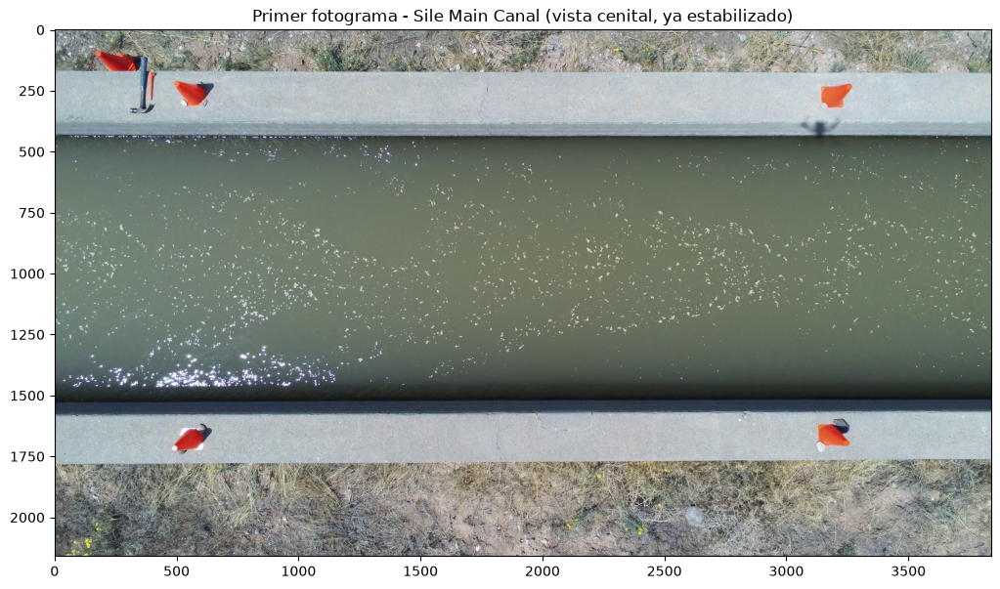

In [2]:
import pyorc

# start_frame/end_frame limitan la lectura: para elegir los puntos de control basta un fotograma.
video = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=1)

# method="rgb" mantiene el color; sin ese argumento saldria en escala de grises, que es lo que
# necesita el PIV pero no ayuda a identificar la linea de agua.
frame = video.get_frame(0, method="rgb")

# Version en gris del mismo fotograma: se usa en la Parte 2 para verificar la linea de agua,
# porque en color la sombra del muro inferior y el agua son casi indistinguibles.
frame_gris = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)

# cv2 se usa solo para leer los metadatos que pyorc no expone directamente.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

ALTO_IMAGEN_PX, ANCHO_IMAGEN_PX = frame.shape[:2]
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {video.fps:.3f}")
print(f"Fotogramas en el video estabilizado: {N_TOTAL} ({N_TOTAL / video.fps:.1f} s)")

# El original solo se consulta para dejar constancia de cuanto se recorto al estabilizar.
if ARCHIVO_VIDEO_CRUDO.exists():
    cap = cv2.VideoCapture(str(ARCHIVO_VIDEO_CRUDO))
    print(f"Fotogramas en el video original del USGS: {int(cap.get(cv2.CAP_PROP_FRAME_COUNT))}")
    cap.release()

plt.figure(figsize=(13, 7))
plt.imshow(frame)
plt.title("Primer fotograma - Sile Main Canal (vista cenital, ya estabilizado)")
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Puntos de control: de pixeles a metros

Aqui esta la diferencia mas grande con Ngwerere. Alli hacian falta **4 puntos** medidos con GPS RTK
porque la camara miraba el rio en escorzo y habia que resolver una homografia completa.

En una vista cenital no hay perspectiva que resolver: la relacion entre pixeles y metros es una
simple **escala mas rotacion**. pyorc lo sabe, y si le pasas exactamente **2 puntos** activa
automaticamente el modo `is_nadir` y construye la transformacion con `estimateAffinePartial2D`, sin
pedir coordenadas RTK ni sistema de referencia.

Los 2 puntos son los extremos de una distancia conocida. Se usa el **ancho de la lamina de agua**:
1.8288 m (6 ft), que es tambien el `Total Width` de la seccion y la misma convencion que uso el
USGS en su procesado con PIVlab (`calibration_distance = 1.8288`).

**Esta es la constante mas influyente del notebook**, porque toda la velocidad, y con ella todo el
caudal, es proporcional a la escala. Diez pixeles de error son un 1 % en el caudal.

### Como se verifica que las dos filas estan bien

Con dos advertencias, y las dos se comprueban en la figura de abajo:

1. Los puntos deben ir sobre la **linea de agua**, donde la lamina toca el muro, no sobre los conos
   naranjas del coronamiento. Los conos estan unos 30 cm mas altos y el modo nadir no modela ese
   desnivel.
2. En el muro inferior se ve una **banda oscura** de unos 85 px entre el agua y el hormigon claro.
   Es la cara interna del muro en sombra, **no es agua**. Tomar el borde inferior de esa banda como
   linea de agua deja la escala un 8 % equivocada, y el caudal con ella.

Por eso la figura no se limita a dibujar los puntos: incluye **ampliaciones en gris con el
contraste estirado** y el **perfil de brillo a lo largo de la columna**, que es donde se ve el
escalon. En el muro superior el escalon es limpio; en el inferior no lo hay, y ese es justo el
motivo de la advertencia 2.

In [3]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Los dos puntos de control y la distancia real entre ellos
# ---------------------------------------------------------------------------------------
# Columna de la imagen sobre la que se leen las dos lineas de agua. Se toma el centro del
# fotograma, lejos de los bordes, donde la distorsion de lente es minima.
COLUMNA_GCP = 1920
# Fila de la linea de agua contra el muro superior (orilla izquierda mirando aguas abajo).
FILA_AGUA_SUP = 438
# Fila de la linea de agua contra el muro inferior (orilla derecha). Aqui no hay escalon
# de brillo: el hormigon queda en sombra y se confunde con el agua oscura, asi que el
# perfil de brillo de la figura siguiente no basta para leerla. El valor viene del
# criterio fisico que aplica el notebook de STIV sobre este mismo video, que no necesita
# la referencia: el agua se mueve y el hormigon no. La desviacion tipica temporal por
# fila, sobre las columnas 600-3400, cae de 7.1 a 1.3 niveles de gris entre las filas
# 1460 y 1465, y cruza el punto medio en la 1463.
FILA_AGUA_INF = 1463
# Las dos filas son las mismas que lee el notebook de STIV sobre este mismo video. Es
# deliberado: si los dos notebooks partieran de escalas distintas, la comparacion entre
# LSPIV y STIV mediria esa diferencia de lectura y no la diferencia entre algoritmos.
# Ancho real de la lamina de agua entre esas dos lineas.  (obtenido del dataset)
ANCHO_CANAL = 1.8288          # m, 6 ft exactos
# ---------------------------------------------------------------------------------------

gcps = dict(
    # Solo DOS puntos: con eso pyorc activa el modo nadir. Ambos en la misma columna, para que
    # el segmento sea perpendicular a los muros.
    src=[
        [COLUMNA_GCP, FILA_AGUA_SUP],
        [COLUMNA_GCP, FILA_AGUA_INF],
    ],
    # Sus coordenadas en un sistema local en metros que inventamos nosotros: el origen en el muro
    # superior y el eje y cruzando el canal. El eje x queda automaticamente a lo largo del canal.
    dst=[
        [0.0, 0.0],
        [0.0, ANCHO_CANAL],
    ],
    h_ref=0.0,  # un solo video, no hay escala limnimetrica que referenciar
    z_0=0.0,    # datum arbitrario: la superficie del agua es la cota cero
)

ANCHO_CANAL_PX = FILA_AGUA_INF - FILA_AGUA_SUP
ESCALA = ANCHO_CANAL / ANCHO_CANAL_PX          # m/px sobre la imagen original

print(f"Ancho del canal en la imagen: {ANCHO_CANAL_PX} px")
print(f"Escala resultante:            {ESCALA * 1000:.3f} mm/px")
print(f"Incertidumbre si la linea de agua se lee con 5 px de error: "
      f"{100 * 5 / ANCHO_CANAL_PX:.2f} % en el caudal")

Ancho del canal en la imagen: 1025 px
Escala resultante:            1.784 mm/px
Incertidumbre si la linea de agua se lee con 5 px de error: 0.49 % en el caudal


---
## Parte 3 - Configuracion de camara, area de interes y reproyeccion

`CameraConfig` recibe los 2 puntos y `crs=None`, porque las coordenadas son locales y no estan
referidas a ningun sistema geografico. Al detectar dos puntos, `set_gcps` marca `is_nadir=True` y
expande internamente el par a las cuatro esquinas de la imagen mediante una semejanza.

Los dos parametros que hay que dimensionar son distintos a los de Ngwerere, porque el canal es diez
veces mas estrecho que el rio. Los dos se eligen por geometria, no por resultado:

- **`resolution`** (metros por pixel de la imagen reproyectada). En Ngwerere eran 0.01 m/px. Aqui
  eso dejaria el canal en 183 px de ancho y muy pocos vectores. Con 0.004 m/px quedan 457 px.
- **`window_size`** (lado de la ventana de interrogacion, en pixeles reproyectados). 32 px a
  0.004 m/px son 12.8 cm, con la malla de vectores cada 6.4 cm por el solape del 50 %. Eso da unos
  28 vectores cruzando el canal. Ventanas mas pequenas resuelven mejor la zona junto a los muros
  pero son mas ruidosas; mas grandes son mas estables pero emborronan los bordes.

Hay una restriccion adicional que fija el limite inferior: el agua avanza unos 18 px por fotograma
en la imagen original, que a 0.004 m/px son unos 8 px reproyectados. La ventana debe ser bastante
mayor que ese desplazamiento, y 32 px lo es.

El **area de interes** se mete por dentro de las dos lineas de agua. No es un ajuste fino: basta con
que no entre hormigon, porque el hormigon esta quieto y produciria vectores de velocidad nula que
el filtrado no siempre elimina.

Area de interes: 5.00 m a lo largo x 1.79 m de ancho
  rango local x: -2.642 .. 2.354 m
  rango local y: 0.023 .. 1.811 m (el canal va de 0 a 1.8288 m)
  vectores a lo ancho del canal: ~28


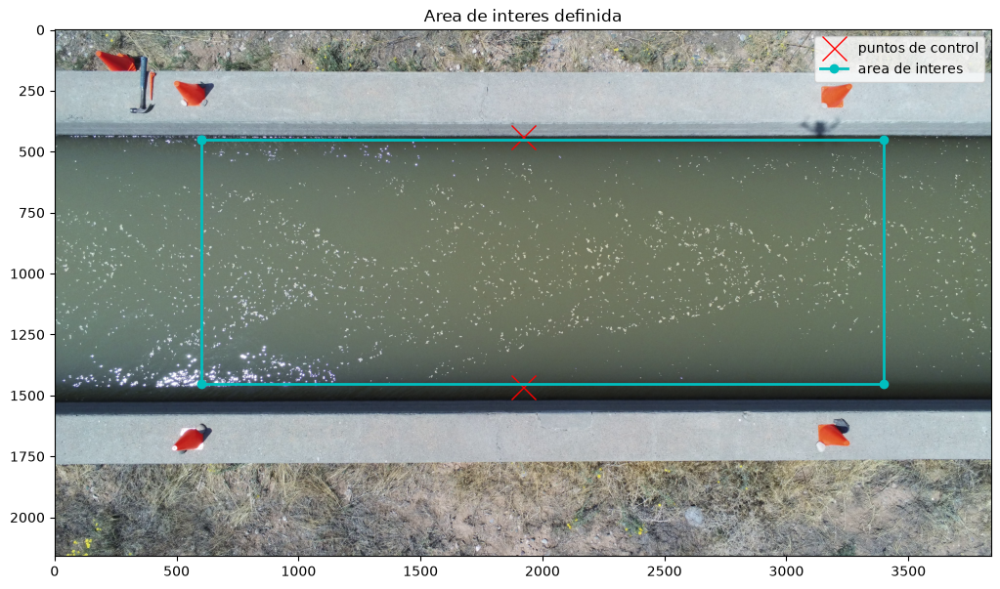


Configuracion de camara guardada en: salidas\cam_config_smc.json


In [4]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Malla de reproyeccion y area de interes
# ---------------------------------------------------------------------------------------
# Tamano del pixel de la imagen ortorectificada. 0.004 m/px deja el canal en ~457 px de ancho.
RESOLUCION = 0.004            # m/px
# Lado de la ventana de interrogacion del PIV, en pixeles reproyectados. 32 px = 12.8 cm.
VENTANA_PIV = 32              # px
# Tramo de columnas util de la imagen: el mismo 600-3400 que muestrea el notebook de STIV.
# Mas largo da mejor estadistica, pero se acerca a los bordes, donde la distorsion de la
# lente del dron es mayor y aqui no hay modelo para corregirla.
COLUMNA_INI, COLUMNA_FIN = 600, 3400
# Las cuatro esquinas del area de interes, en pixeles [columna, fila] de la imagen original.
# El orden que espera pyorc es: aguas-arriba-izquierda, aguas-abajo-izquierda,
# aguas-abajo-derecha, aguas-arriba-derecha (mirando aguas abajo, que aqui es hacia la derecha).
# Las filas van unos 12 px por dentro de cada linea de agua para que no entre hormigon: eso
# si es propio del PIV, cuyas ventanas de interrogacion no pueden tocar el muro.
ESQUINAS_AOI = [
    [COLUMNA_INI, FILA_AGUA_SUP + 12],
    [COLUMNA_FIN, FILA_AGUA_SUP + 12],
    [COLUMNA_FIN, FILA_AGUA_INF - 10],
    [COLUMNA_INI, FILA_AGUA_INF - 10],
]
# ---------------------------------------------------------------------------------------

# height y width se toman del propio fotograma para no escribirlos a mano.
cam_config = pyorc.CameraConfig(
    height=ALTO_IMAGEN_PX,
    width=ANCHO_IMAGEN_PX,
    gcps=gcps,
    crs=None,  # coordenadas locales en metros: no hay CRS geografico (en Ngwerere era 32735)
)
cam_config.resolution = RESOLUCION
cam_config.window_size = VENTANA_PIV
cam_config.set_bbox_from_corners(ESQUINAS_AOI)

# El bbox ya esta en coordenadas locales; de aqui sale donde colocar el transecto.
x_bbox, y_bbox = np.array(cam_config.bbox.exterior.coords).T
print(f"Area de interes: {x_bbox.max() - x_bbox.min():.2f} m a lo largo x "
      f"{y_bbox.max() - y_bbox.min():.2f} m de ancho")
print(f"  rango local x: {x_bbox.min():.3f} .. {x_bbox.max():.3f} m")
print(f"  rango local y: {y_bbox.min():.3f} .. {y_bbox.max():.3f} m "
      f"(el canal va de 0 a {ANCHO_CANAL} m)")
print(f"  vectores a lo ancho del canal: ~{int(ANCHO_CANAL / RESOLUCION / (VENTANA_PIV / 2))}")

fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(frame)
ax.plot(*zip(*gcps["src"]), "rx", markersize=18, label="puntos de control")
esq = np.array(ESQUINAS_AOI + [ESQUINAS_AOI[0]])
ax.plot(esq[:, 0], esq[:, 1], "c-o", lw=2, label="area de interes")
ax.legend()
ax.set_title("Area de interes definida")
plt.savefig(DIR_SALIDA / "fig3_area_interes.png", dpi=110, bbox_inches="tight")
plt.show()

cam_config.to_file(str(SALIDA_CAM_CONFIG))
print(f"\nConfiguracion de camara guardada en: {SALIDA_CAM_CONFIG}")

Scanning video: 100%|██████████| 2/2 [00:03<00:00,  1.52s/it]


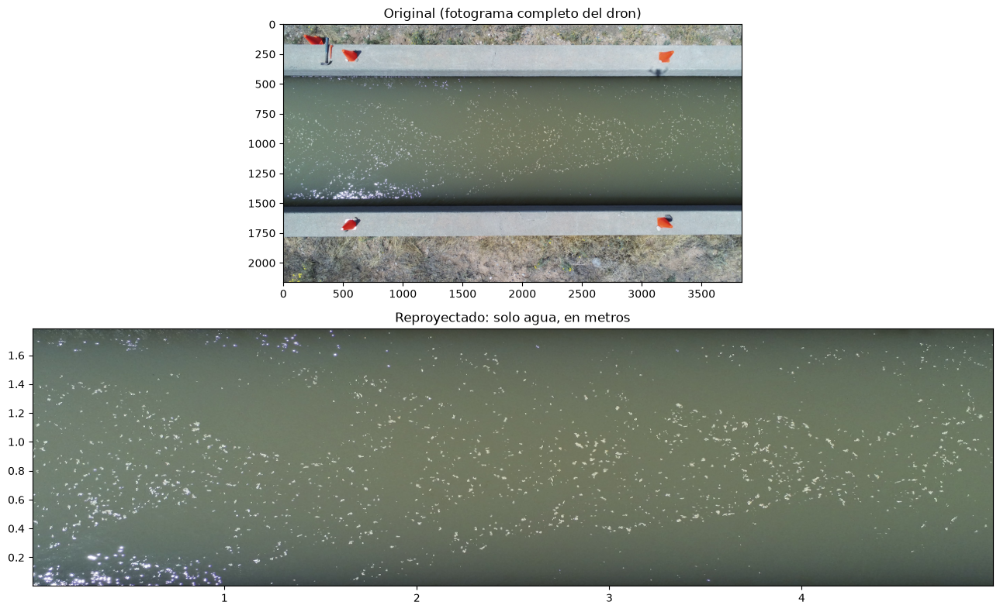

In [5]:
# Comprobacion de que la reproyeccion funciona, con un solo fotograma.
video_demo = pyorc.Video(
    str(ARCHIVO_VIDEO),
    camera_config=cam_config,
    start_frame=0,
    end_frame=1,
    h_a=0.0,  # nivel del agua de ESTE video respecto a h_ref (mismo video: 0)
)

da_rgb_demo = video_demo.get_frames(method="rgb")
da_rgb_proj_demo = da_rgb_demo.frames.project()

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
axes[0].imshow(frame)
axes[0].set_title("Original (fotograma completo del dron)")
da_rgb_proj_demo[0].frames.plot(ax=axes[1])
axes[1].set_title("Reproyectado: solo agua, en metros")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_reproyeccion.png", dpi=110, bbox_inches="tight")
plt.show()

# En una vista cenital el "antes" y el "despues" se parecen mucho: no hay escorzo que corregir,
# solo un recorte, un giro pequeno y un cambio de unidades de pixeles a metros.

---
## Parte 4 - Velocidades superficiales con LSPIV

La cadena es la de siempre en pyorc: pasar a gris, normalizar, reproyectar y correlacionar pares de
fotogramas consecutivos. No hay que pasar `stabilize=`, porque el video de entrada viene corregido.

Se procesan 250 de los 672 fotogramas disponibles (8.3 s). Es el doble que en Ngwerere porque aqui
hay margen de sobra y promediar mas tiempo estabiliza los cuantiles; el USGS uso 687 en su propio
procesado. Subirlo a 672 mejora poco y cuesta el triple.

### Donde se gasta el tiempo de verdad

Esta parte esta envuelta en `benchmark.medir(...)`, y midiendo cada bloque por separado aparece
algo que conviene saber.

La documentacion de `get_piv` dice literalmente que solo monta el grafo de calculo y que el
resultado sale *"in a lazy dask.array form"*, de modo que el trabajo se dispararia al pedir un
resultado, tipicamente en `to_netcdf`. **Medido sobre pyorc 0.9.8, eso no es asi.** Comprobando
que tipo de array devuelve cada paso:

| Paso | Devuelve | Interpretacion |
|---|---|---|
| `get_frames` | dask | perezoso, como dice la documentacion |
| `normalize` | dask | perezoso |
| `project` | dask | perezoso |
| `get_piv` | **numpy** | **calcula en el momento** |

Por eso el reparto de tiempos de la Parte 6 sale al reves de lo esperado: `get_piv` se lleva la
mayor parte y `to_netcdf` tarda decimas de segundo, porque cuando llega ya no queda nada que
calcular. Los tres pasos perezosos tampoco son gratis, porque construir el grafo obliga a leer y
recorrer los fotogramas.

La consecuencia practica: el **pico de memoria** se alcanza dentro de `get_piv`, no al escribir. Es
el numero a vigilar antes de subir `N_FRAMES`.

In [ ]:
from dask.diagnostics import ProgressBar

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa
# ---------------------------------------------------------------------------------------
# Numero de fotogramas a correlacionar. Mas fotogramas estabilizan los cuantiles y cuestan
# tiempo y memoria de forma casi lineal. 250 son 8.3 s de video.
N_FRAMES = 250
# ---------------------------------------------------------------------------------------

# Se recarga la configuracion desde el JSON recien escrito. Es la prueba de que el archivo
# guardado es completo y de que a partir de aqui no depende nada de las celdas anteriores.
cam_config = pyorc.load_camera_config(str(SALIDA_CAM_CONFIG))

with benchmark.medir("Parte 4: abrir video y get_frames", n_frames=N_FRAMES):
    video = pyorc.Video(
        str(ARCHIVO_VIDEO),
        camera_config=cam_config,
        start_frame=0,
        end_frame=N_FRAMES,
        # Sin stabilize=: el video de entrada ya viene corregido por estabilizar_video.py.
        h_a=0.0,
    )
    # Sin method="rgb" los fotogramas salen en escala de grises, que es lo que necesita el PIV.
    da = video.get_frames()

print(f"Procesando {N_FRAMES} fotogramas de {da.shape[1]}x{da.shape[2]} px")

with benchmark.medir("Parte 4: normalize + project (monta el grafo)", n_frames=N_FRAMES):
    # Resta el fondo (media de varios fotogramas) para realzar los trazadores en movimiento.
    # En este canal los trazadores son espuma y burbujas, muy contrastados; el USGS ademas
    # aplico CLAHE, que pyorc no necesita porque normalize ya iguala la iluminacion.
    da_norm = da.frames.normalize()
    # Ortorectifica cada fotograma a la malla del AOI.
    da_norm_proj = da_norm.frames.project(method="numpy")

print("\nCalculando velocidades (PIV)...")
with benchmark.medir("Parte 4: get_piv (calcula de verdad)", n_frames=N_FRAMES), ProgressBar():
    # Pese a lo que dice su documentacion, aqui es donde se calcula el PIV: devuelve arrays
    # de numpy, no de dask. Es el bloque que marca el pico de memoria de todo el notebook.
    piv = da_norm_proj.frames.get_piv()

with benchmark.medir("Parte 4: to_netcdf (escribir a disco)", n_frames=N_FRAMES):
    # En un pipeline perezoso esta seria la linea cara; aqui solo escribe, porque get_piv
    # ya dejo los resultados calculados en memoria.
    piv.to_netcdf(SALIDA_PIV_CRUDO)

print(f"\nVelocimetria cruda guardada en: {SALIDA_PIV_CRUDO}")

Scanning video: 100%|██████████| 251/251 [00:33<00:00,  7.55it/s]


  [bench] Parte 4: abrir video y get_frames: 39.9 s | CPU 182.9 s (4.6 nucleos) | RAM pico 1238 MB
Procesando 250 fotogramas de 2160x3840 px
  [bench] Parte 4: normalize + project (monta el grafo): 77.8 s | CPU 470.1 s (6.0 nucleos) | RAM pico 7540 MB

Calculando velocidades (PIV)...


Computing PIV per chunk:   0%|          | 0/2 [00:00<?, ?it/s]

[########################################] | 100% Completed | 44.09 s


Computing PIV per chunk:  50%|█████     | 1/2 [00:55<00:55, 55.59s/it]

[##########################              ] | 66% Completed | 29.27 ss


Computing PIV per chunk:  50%|█████     | 1/2 [01:24<01:24, 84.93s/it]

  [bench] Parte 4: get_piv (calcula de verdad): 85.0 s | CPU 626.3 s (7.4 nucleos) | RAM pico 11209 MB


Dimensiones del resultado PIV: {'time': 250, 'y': 26, 'x': 77}



Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]


Scanning video:  50%|█████     | 1/2 [00:00<00:00,  1.95it/s]


Scanning video: 100%|██████████| 2/2 [00:00<00:00,  3.57it/s]


Scanning video: 100%|██████████| 2/2 [00:02<00:00,  1.06s/it]

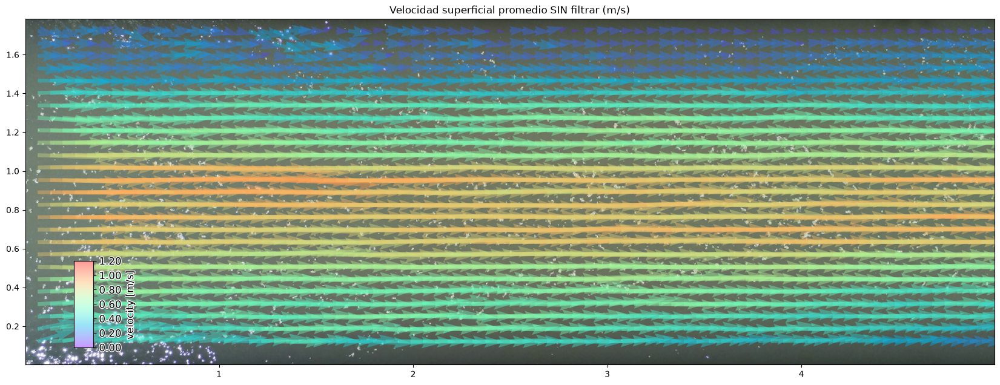

In [ ]:
import xarray as xr
from matplotlib.colors import Normalize

# Se relee desde el NetCDF: el dataset trae v_x, v_y, s2n y corr, mas la config de camara
# embebida en los atributos.
ds = xr.open_dataset(SALIDA_PIV_CRUDO)
print(f"Dimensiones del resultado PIV: {dict(ds.sizes)}")

# Fondo en color para dibujar encima.
video_rgb = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=1)
video_rgb.camera_config = ds.velocimetry.camera_config
da_rgb = video_rgb.get_frames(method="rgb")
da_rgb_proj = da_rgb.frames.project()

# keep_attrs=True conserva la config de camara y los metadatos, necesarios para plotear.
ds_mean = ds.mean(dim="time", keep_attrs=True)

# La escala de color llega a 1.2 m/s: aqui el agua va a ~0.95 m/s, frente a los 0.6 de Ngwerere.
NORMA_COLOR = Normalize(vmin=0.0, vmax=1.2, clip=False)

p = da_rgb_proj[0].frames.plot()
ds_mean.velocimetry.plot(ax=p.axes, alpha=0.4, norm=NORMA_COLOR, add_colorbar=True)
plt.title("Velocidad superficial promedio SIN filtrar (m/s)")
plt.savefig(DIR_SALIDA / "fig5_velocidades_sin_filtrar.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4b - Filtrado de velocidades espurias

Se aplican las mascaras de pyorc en el orden en que la propia libreria las encadena, porque cada
una condiciona a la siguiente cuando se usan con `inplace=True`: primero las que miran valores
sueltos, luego las que miran la serie temporal de cada celda, y al final las que necesitan la
vecindad espacial.

Todas se usan con sus **parametros por defecto**, salvo dos decisiones que si son de este caso:

- **La mascara de angulo se aplica.** En el notebook de Ngwerere se calculaba y se descartaba, a
  proposito, para reproducir el resultado publicado del ejemplo 03. Aqui no existe esa atadura, y
  ademas el caso la pide: un canal recto de hormigon con flujo unidireccional es el escenario ideal
  para esta mascara. Se usa la tolerancia por defecto de 0.25*pi (45 grados).
- **La direccion esperada se deduce del propio campo.** El signo del eje x local depende de en que
  orden se marcaron los dos puntos de control, asi que fijarlo a mano seria una fuente de errores
  silenciosos. Se toma del signo de la velocidad media, que no es un ajuste: es leer en que
  direccion va el agua.

Velocidad media v_x = +0.585 m/s -> angle_expected = 1.571 rad


  [bench] Parte 4b: mascaras de filtrado: 0.5 s | CPU 0.5 s (1.0 nucleos) | RAM pico 1224 MB

Vectores validos antes del filtrado: 496375
Vectores validos despues:            281464 (56.7 %)


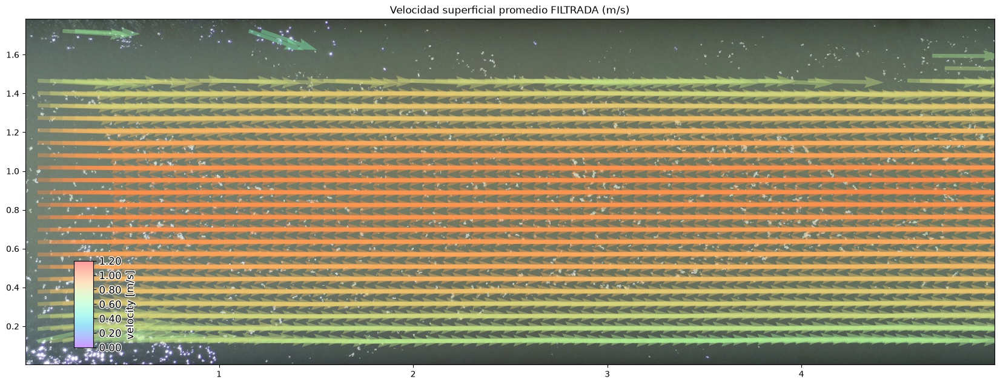

Velocimetria filtrada guardada en: salidas\piv_filtrado.nc


In [ ]:
with benchmark.medir("Parte 4b: mascaras de filtrado", n_frames=N_FRAMES):
    # deepcopy para conservar intacto el dataset crudo y poder comparar despues.
    ds_mask = copy.deepcopy(ds)

    # Direccion dominante del flujo en el sistema local. angle_expected se mide en radianes en
    # sentido horario desde el eje vertical: 0.5*pi es "hacia +x", 1.5*pi es "hacia -x".
    angulo_esperado = 0.5 * np.pi if float(ds["v_x"].mean()) > 0 else 1.5 * np.pi
    print(f"Velocidad media v_x = {float(ds['v_x'].mean()):+.3f} m/s "
          f"-> angle_expected = {angulo_esperado:.3f} rad")

    # Las mascaras se aplican sobre datos ya en memoria, asi que aqui no hay pereza que valga:
    # el coste es real y se nota sobre todo en window_mean, que recorre la vecindad espacial.
    # --- 1) mascaras sobre valores individuales ---
    ds_mask.velocimetry.mask.corr(inplace=True)      # correlacion demasiado baja
    ds_mask.velocimetry.mask.minmax(inplace=True)    # velocidades fuera de rango plausible

    # --- 2) mascaras en el dominio del tiempo ---
    ds_mask.velocimetry.mask.rolling(inplace=True)   # contra la media movil de la propia celda
    ds_mask.velocimetry.mask.outliers(inplace=True)  # lejos de la media temporal de la celda
    ds_mask.velocimetry.mask.variance(inplace=True)  # varianza temporal inverosimil

    # --- 3) direccion del flujo (esta si se aplica, a diferencia de Ngwerere) ---
    ds_mask.velocimetry.mask.angle(angle_expected=angulo_esperado,
                                   angle_tolerance=0.25 * np.pi, inplace=True)

    # --- 4) mascaras que necesitan toda la serie o la vecindad espacial ---
    ds_mask.velocimetry.mask.count(inplace=True)     # celdas con muy pocos valores validos
    ds_mask.velocimetry.mask.window_mean(wdw=2, inplace=True, tolerance=0.5, reduce_time=True)

ds_mean_mask = ds_mask.mean(dim="time", keep_attrs=True)

n_antes = int(ds["v_x"].count())
n_despues = int(ds_mask["v_x"].count())
print(f"\nVectores validos antes del filtrado: {n_antes}")
print(f"Vectores validos despues:            {n_despues} ({100 * n_despues / n_antes:.1f} %)")

p = da_rgb_proj[0].frames.plot()
ds_mean_mask.velocimetry.plot(ax=p.axes, alpha=0.4, norm=NORMA_COLOR, add_colorbar=True)
plt.title("Velocidad superficial promedio FILTRADA (m/s)")
plt.savefig(DIR_SALIDA / "fig6_velocidades_filtradas.png", dpi=110, bbox_inches="tight")
plt.show()

# Se guarda el campo filtrado sin set_encoding(), para que el archivo contenga exactamente los
# mismos valores en coma flotante que usan las celdas siguientes.
ds_mask.to_netcdf(SALIDA_PIV_FILTRADO)
print(f"Velocimetria filtrada guardada en: {SALIDA_PIV_FILTRADO}")

---
## Parte 5 - Seccion transversal y caudal

En Ngwerere la batimetria venia de un levantamiento con RTK. Aqui no hay levantamiento: el canal es
una caja de hormigon de paredes verticales, y la seccion se lee directamente del CSV del data
release (`Station_Stage_SileCanal.csv`), que da 13 verticales con su progresiva desde la orilla
izquierda y su profundidad.

### Por que la seccion tiene profundidad cero en los extremos

El CSV registra las dos verticales de los extremos con **profundidad 0**. No es un error: es la
convencion **mid-section** con la que se levanta cualquier seccion de aforo, donde la primera y la
ultima vertical marcan el borde del agua. En un cauce natural la orilla sube en pendiente y esa
convencion es casi exacta; en una caja de hormigon de paredes verticales no lo es.

La consecuencia es que la seccion del CSV mide 1.803 m2 y no los 1.962 m2 que tiene fisicamente la
caja (1.8288 x 1.073). La diferencia, un 9 %, son las dos franjas de 7.6 cm junto a cada muro que
la convencion descarta.

**Este notebook usa la seccion tal como la da el dataset**, sin retocarla: son los 13 puntos del
CSV con sus progresivas tal cual, que es lo mismo que integra el notebook de STIV sobre este
video, y pyorc los integra por trapecios reproduciendo exactamente esos 1.803 m2. La caja fisica
completa se dibuja al lado, para que se vea de que se esta hablando, pero no entra en ningun
calculo. Elegir una u otra no es un ajuste del metodo sino un cambio de convencion, y la del CSV es
la que corresponde a la geometria que el dataset describe.

### El coeficiente `v_corr`

`v_corr` convierte la velocidad **superficial** que mide el LSPIV en la velocidad **media en la
vertical**, que es la que multiplica al area para dar caudal. Es el unico parametro del pipeline
que no se puede medir en la imagen, porque depende del perfil vertical de velocidades, y ninguna
tecnica de velocimetria superficial puede resolverlo sin informacion de la vertical.

Se usa **0.92**, el mismo valor que el notebook de STIV aplica sobre este mismo video. La razon es
que los dos notebooks estan pensados para compararse entre si: si uno usara 0.9 (el valor por
defecto de pyorc, el que uso Ngwerere) y el otro 0.92, parte de la diferencia entre ambos seria
solo el convenio, no el algoritmo. Se fija aqui, antes de mirar ningun resultado. El aforo permite
estimar a posteriori cuanto habria salido en este canal concreto, y ese calculo esta en la Parte 7,
pero **no se usa para corregir nada**.

In [ ]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria de la seccion y paso de superficial a media en la vertical
# ---------------------------------------------------------------------------------------
# Profundidad del canal, constante en todas las verticales: caja rectangular de hormigon.
# Solo se usa para dibujar la caja fisica, no entra en el calculo.  (obtenido del dataset)
PROFUNDIDAD = 1.073           # m
# Cociente entre la velocidad media en la vertical y la superficial. Es el unico parametro
# del notebook que NO se puede medir en la imagen. Se usa 0.92, el mismo valor que el
# notebook de STIV sobre este video, para que la comparacion entre los dos algoritmos no
# mezcle una diferencia de convenio con una diferencia de metodo. Se fija aqui, antes de
# mirar ninguna referencia, y no se toca despues.
V_CORR = 0.92                 # -
# ---------------------------------------------------------------------------------------

# El CSV trae las 13 verticales del levantamiento: progresiva desde la orilla izquierda y
# profundidad. Se usan tal cual, sin regenerar las progresivas desde el paso de 0.5 ft: son
# las mismas coordenadas que integra el notebook de STIV, y por tanto la misma seccion.
seccion = pd.read_csv(ARCHIVO_SECCION)
print(seccion.to_string(index=False))

s_transecto = seccion["Progresiva"].to_numpy(float)
prof_transecto = seccion["Prof"].to_numpy(float)
N_VERTICALES = len(s_transecto)

# Las verticales de profundidad nula son los extremos: no son medida de velocidad, son el
# borde del agua. Misma regla que en el notebook de STIV.
ES_CONTORNO = prof_transecto == 0.0

AREA_SECCION = float(np.trapezoid(prof_transecto, s_transecto))   # la que usa pyorc
AREA_CAJA = 1.7988                             # la caja fisica, informativa

print(f"\nVerticales: {N_VERTICALES}, de s = 0 a s = {s_transecto[-1]:.4f} m")
print(f"Area de la seccion del CSV (la que se usa): {AREA_SECCION:.4f} m2")
print(f"Area de la caja fisica (solo informativa) : {AREA_CAJA:.4f} m2 "
      f"({100 * (AREA_CAJA / AREA_SECCION - 1):+.1f} %)")

 Progresiva  Prof
       0.00 0.000
       0.15 1.073
       0.30 1.073
       0.46 1.073
       0.61 1.073
       0.76 1.073
       0.91 1.073
       1.07 1.073
       1.22 1.073
       1.37 1.073
       1.52 1.073
       1.68 1.073
       1.83 0.000

Verticales: 13, de s = 0 a s = 1.8300 m
Area de la seccion del CSV (la que se usa): 1.8026 m2
Area de la caja fisica (solo informativa) : 1.7988 m2 (-0.2 %)


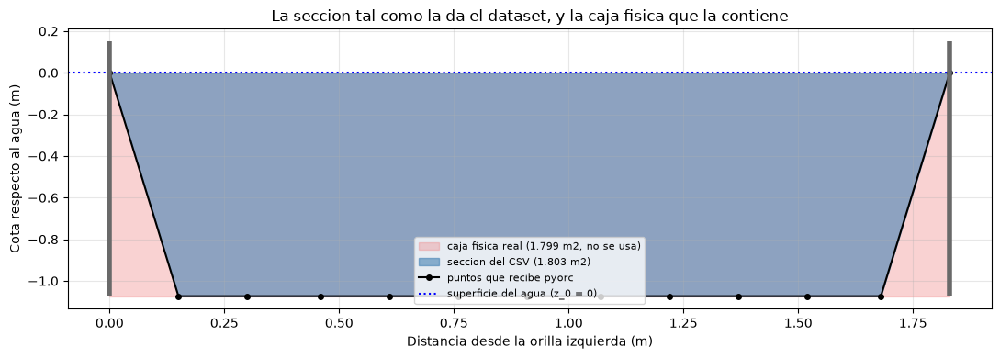

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))

# La caja fisica, de muro a muro: solo para ver que descarta la convencion mid-section.
ax.fill_between([0, ANCHO_CANAL], [-PROFUNDIDAD] * 2, 0,
                color="lightcoral", alpha=0.35,
                label=f"caja fisica real ({AREA_CAJA:.3f} m2, no se usa)")
# La seccion del CSV, que es la que recibe pyorc.
ax.fill_between(s_transecto, -prof_transecto, 0,
                color="steelblue", alpha=0.6,
                label=f"seccion del CSV ({AREA_SECCION:.3f} m2)")
ax.plot(s_transecto, -prof_transecto, "k-o", ms=4, lw=1.5, label="puntos que recibe pyorc")
ax.axhline(0, color="b", ls=":", lw=1.5, label="superficie del agua (z_0 = 0)")

# Los muros verticales, para que se vea que la caja llega hasta ellos.
for xm in (0, ANCHO_CANAL):
    ax.plot([xm, xm], [-PROFUNDIDAD, 0.15], color="dimgray", lw=4, solid_capstyle="butt")

ax.set_xlabel("Distancia desde la orilla izquierda (m)")
ax.set_ylabel("Cota respecto al agua (m)")
ax.set_title("La seccion tal como la da el dataset, y la caja fisica que la contiene")
ax.legend(fontsize=8, loc="lower center")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_seccion.png", dpi=110, bbox_inches="tight")
plt.show()

### Muestreo del transecto

Dos diferencias con la llamada de Ngwerere:

- **No se pasa `crs`.** Alli la batimetria estaba en UTM 35S y habia que declararlo; aqui las
  coordenadas ya estan en el sistema local del propio `CameraConfig`.
- **Se pasa `s=`.** Sin ese argumento pyorc remuestrea la seccion a la resolucion de la malla de
  velocidades, y en Ngwerere eso estaba bien porque la batimetria tenia mas detalle que la malla.
  Aqui pasa lo contrario: la seccion tiene 13 puntos y la malla mucho mas, asi que remuestrear
  inventaria geometria. `s=` fija las distancias del CSV y evita el remuestreo.

`get_q` rellena los huecos con `fill_method="log_interp"`, el metodo por defecto de pyorc: donde no
hay velocidad valida la reconstruye con un perfil logaritmico en funcion de la distancia al borde.
Hace falta casi con seguridad, porque las ventanas de interrogacion pegadas al hormigon pierden
correlacion y se quedan sin dato. Cuantas verticales acaban siendo relleno y cuantas medida se
imprime al final de la celda: es la debilidad conocida de este caso.

In [ ]:
# El transecto se coloca en mitad del area de interes, perpendicular al flujo: x constante,
# y recorriendo el ancho del canal.
X_TRANSECTO = float(0.5 * (x_bbox.min() + x_bbox.max()))

x_pts = np.full(N_VERTICALES, X_TRANSECTO)
y_pts = s_transecto                 # el eje y local ES la distancia desde la orilla izquierda
z_pts = -prof_transecto             # z_0 = 0, asi que la cota del lecho es la profundidad negada

with benchmark.medir("Parte 5: get_transect + get_q", n_frames=N_FRAMES):
    # El muestreo se hace sobre ds_mask (filtrado), NO sobre ds (crudo).
    transect = ds_mask.velocimetry.get_transect(
        x_pts.tolist(),
        y_pts.tolist(),
        z_pts.tolist(),
        s=s_transecto.tolist(),  # respeta las 13 verticales exactas, sin remuestrear
        rolling=4,               # media movil de 4 pasos de tiempo antes de los cuantiles
        # wdw=1 (por defecto) toma la mediana de una ventana de 3x3 celdas alrededor de cada punto.
    )
    q_transect = transect.transect.get_q(v_corr=V_CORR, fill_method="log_interp")
    # get_river_flow integra q a lo ancho de la seccion y anade river_flow al dataset.
    q_transect.transect.get_river_flow()

q_med = q_transect.sel(quantile=0.5)
v_eff = q_med["v_eff"].values                    # superficial, con huecos rellenados
v_eff_medida = q_med["v_eff_nofill"].values      # solo donde hubo medida valida
medida = np.isfinite(v_eff_medida) & ~ES_CONTORNO

print(f"Transecto colocado en x = {X_TRANSECTO:.3f} m")
print(f"Puntos del transecto: {transect.sizes['points']} (las {N_VERTICALES} verticales del CSV)")
print(f"Cuantiles calculados: {transect['quantile'].values}")
print(f"\nVerticales con velocidad medida: {int(medida.sum())} de "
      f"{int((~ES_CONTORNO).sum())} interiores")
print("El resto lo rellena el perfil logaritmico, y son siempre las pegadas a los muros.")

  [bench] Parte 5: get_transect + get_q: 2.4 s | CPU 2.3 s (1.0 nucleos) | RAM pico 1404 MB
Transecto colocado en x = -0.144 m
Puntos del transecto: 13 (las 13 verticales del CSV)
Cuantiles calculados: [0.05 0.25 0.5  0.75 0.95]

Verticales con velocidad medida: 8 de 11 interiores
El resto lo rellena el perfil logaritmico, y son siempre las pegadas a los muros.


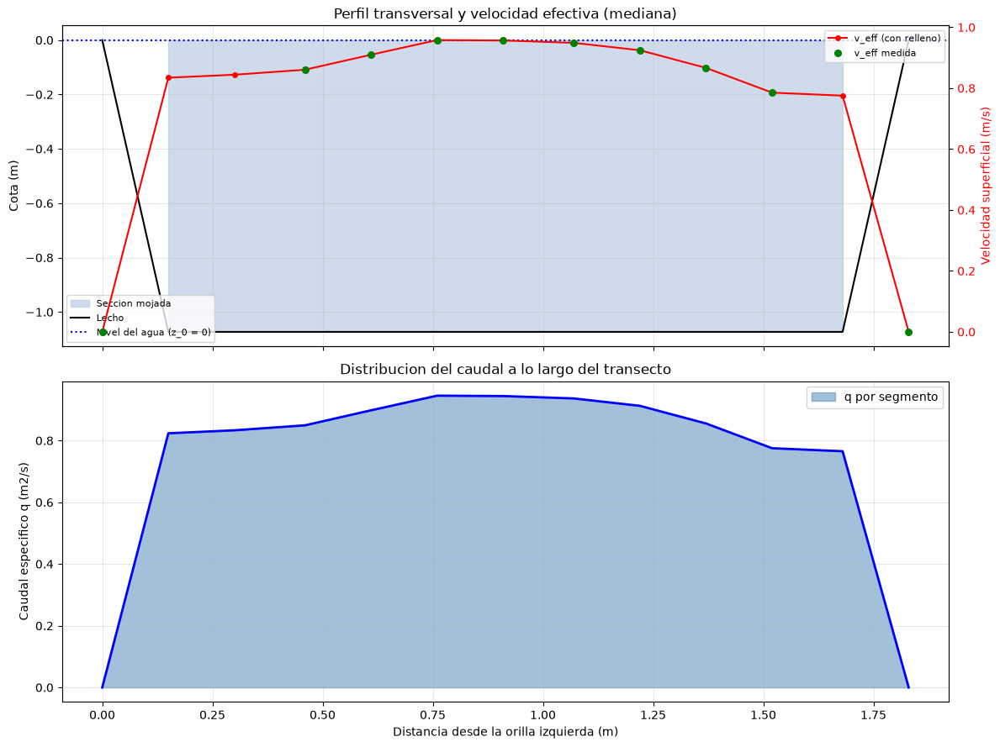

In [ ]:
s = q_med["scoords"].values

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# --- Panel superior: geometria de la seccion y velocidad efectiva ---
ax_z = axes[0]
ax_z.fill_between(s, q_med["zcoords"].values, 0.0,
                  where=q_med["zcoords"].values < 0.0,
                  color="lightsteelblue", alpha=0.6, label="Seccion mojada")
ax_z.plot(s, q_med["zcoords"].values, "k-", lw=1.5, label="Lecho")
ax_z.axhline(0.0, color="b", ls=":", lw=1.5, label="Nivel del agua (z_0 = 0)")
ax_z.set_ylabel("Cota (m)")
ax_z.set_title("Perfil transversal y velocidad efectiva (mediana)")
ax_z.legend(loc="lower left", fontsize=8)
ax_z.grid(alpha=0.3)

ax_v = ax_z.twinx()
ax_v.plot(s, v_eff, "r-o", ms=4, lw=1.5, label="v_eff (con relleno)")
# Los huecos delatan cuanto del perfil es interpolacion y cuanto medida.
ax_v.plot(s, v_eff_medida, "g.", ms=11, label="v_eff medida")
ax_v.set_ylabel("Velocidad superficial (m/s)", color="r")
ax_v.tick_params(axis="y", labelcolor="r")
ax_v.legend(loc="upper right", fontsize=8)

# --- Panel inferior: caudal especifico ---
axes[1].fill_between(s, q_med["q"].values, alpha=0.5, color="steelblue", label="q por segmento")
axes[1].plot(s, q_med["q"].values, "b-", lw=2)
axes[1].set_xlabel("Distancia desde la orilla izquierda (m)")
axes[1].set_ylabel("Caudal especifico q (m2/s)")
axes[1].set_title("Distribucion del caudal a lo largo del transecto")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_perfil_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

In [ ]:
caudal = q_transect["river_flow"]

Q_PYORC = float(caudal.sel(quantile=0.50))
q_05 = float(caudal.sel(quantile=0.05))
q_95 = float(caudal.sel(quantile=0.95))

print("=" * 52)
print("CAUDAL POR CUANTIL (m3/s)")
print("=" * 52)
for qt in caudal["quantile"].values:
    print(f"{qt:>8.2f} {float(caudal.sel(quantile=qt)):>12.4f}")
print("-" * 52)
print(f"Caudal (mediana):    {Q_PYORC:.4f} m3/s")
print(f"Banda del PIV:       P5 = {q_05:.4f}   P95 = {q_95:.4f}  "
      f"({100 * (q_05 / Q_PYORC - 1):+.1f} % .. {100 * (q_95 / Q_PYORC - 1):+.1f} %)")
print(f"Velocidad media:     {Q_PYORC / AREA_SECCION:.4f} m/s")
print("=" * 52)

# El perfil vertical a vertical, para poder reanalizar sin repetir el PIV.
perfil = pd.DataFrame({
    "vertical": np.arange(N_VERTICALES),
    "s_m": s_transecto,
    "prof_m": prof_transecto,
    "v_sup_medida_ms": v_eff_medida,
    "v_sup_usada_ms": v_eff,
    "v_media_vertical_ms": v_eff * V_CORR,
    "q_especifico_m2s": q_med["q"].values,
    "origen": np.where(ES_CONTORNO, "contorno (v=0 por convenio)",
                       np.where(medida, "medida", "relleno log_interp")),
})
perfil.to_csv(SALIDA_PERFIL, index=False)
print(f"\nPerfil guardado en: {SALIDA_PERFIL}")
perfil

CAUDAL POR CUANTIL (m3/s)
    0.05       1.3532
    0.25       1.4114
    0.50       1.4565
    0.75       1.5069
    0.95       1.5754
----------------------------------------------------
Caudal (mediana):    1.4565 m3/s
Banda del PIV:       P5 = 1.3532   P95 = 1.5754  (-7.1 % .. +8.2 %)
Velocidad media:     0.8080 m/s

Perfil guardado en: salidas\perfil_transecto.csv


,vertical,s_m,prof_m,v_sup_medida_ms,v_sup_usada_ms,v_media_vertical_ms,q_especifico_m2s,origen
0,0,0.00,0.000,0.000000,0.000000,0.000000,0.000000,contorno (v=0 por convenio)
1,1,0.15,1.073,NaN,0.834340,0.767593,0.823627,relleno log_interp
2,2,0.30,1.073,NaN,0.844129,0.776598,0.833290,relleno log_interp
3,3,0.46,1.073,0.860491,0.860491,0.791651,0.849442,medida
4,4,0.61,1.073,0.909751,0.909751,0.836971,0.898070,medida
5,5,0.76,1.073,0.957837,0.957837,0.881210,0.945538,medida
6,6,0.91,1.073,0.956585,0.956585,0.880058,0.944302,medida
7,7,1.07,1.073,0.948718,0.948718,0.872821,0.936537,medida
8,8,1.22,1.073,0.924473,0.924473,0.850515,0.912603,medida
9,9,1.37,1.073,0.866579,0.866579,0.797252,0.855452,medida


In [ ]:
# El transecto completo se guarda tambien en NetCDF: contiene v_eff, q, river_flow y todas
# las coordenadas del muestreo.
q_transect.to_netcdf(SALIDA_TRANSECTO)

# Y la configuracion completa se congela en un JSON. Es lo que hace reproducible el resultado:
# cualquier numero que cambie el caudal esta aqui dentro.
config = dict(
    video=str(ARCHIVO_VIDEO),
    n_frames=N_FRAMES,
    fps=float(video.fps),
    columna_gcp=COLUMNA_GCP,
    fila_agua_sup=FILA_AGUA_SUP,
    fila_agua_inf=FILA_AGUA_INF,
    ancho_canal_m=ANCHO_CANAL,
    escala_m_px=ESCALA,
    resolucion_m_px=RESOLUCION,
    ventana_piv_px=VENTANA_PIV,
    esquinas_aoi=ESQUINAS_AOI,
    columna_ini=COLUMNA_INI,
    columna_fin=COLUMNA_FIN,
    profundidad_m=PROFUNDIDAD,
    v_corr=V_CORR,
    area_seccion_m2=AREA_SECCION,
    x_transecto_m=X_TRANSECTO,
    caudal_mediana_m3s=Q_PYORC,
)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")

print(f"Transecto guardado en:      {SALIDA_TRANSECTO}")
print(f"Configuracion congelada en: {SALIDA_CONFIG}")

Transecto guardado en:      salidas\transecto_caudal.nc
Configuracion congelada en: salidas\config_pyorc.json


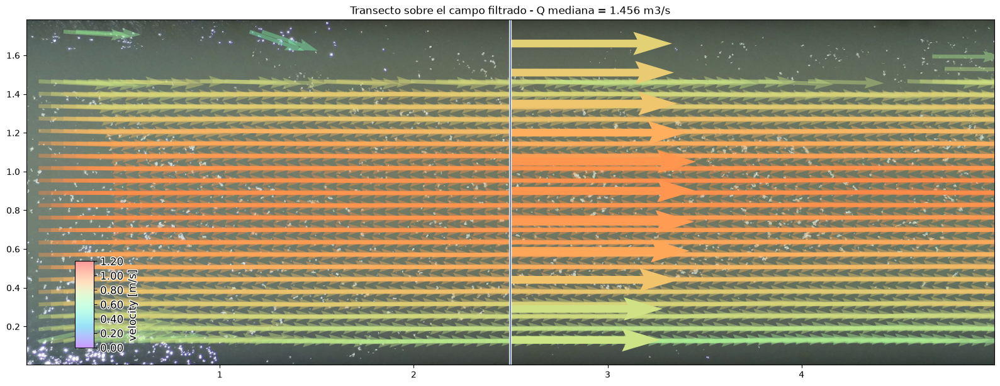

In [ ]:
# Mapa final: transecto sobre el campo de velocidades filtrado, en coordenadas locales.
p = da_rgb_proj[0].frames.plot(mode="local")
ds_mean_mask.velocimetry.plot(ax=p.axes, mode="local", alpha=0.4, norm=NORMA_COLOR,
                              add_colorbar=True)
q_transect.sel(quantile=0.5).transect.plot(ax=p.axes, mode="local", cmap="rainbow",
                                           norm=NORMA_COLOR, width=2)
p.axes.set_title(f"Transecto sobre el campo filtrado - Q mediana = {Q_PYORC:.3f} m3/s")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig9_mapa_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

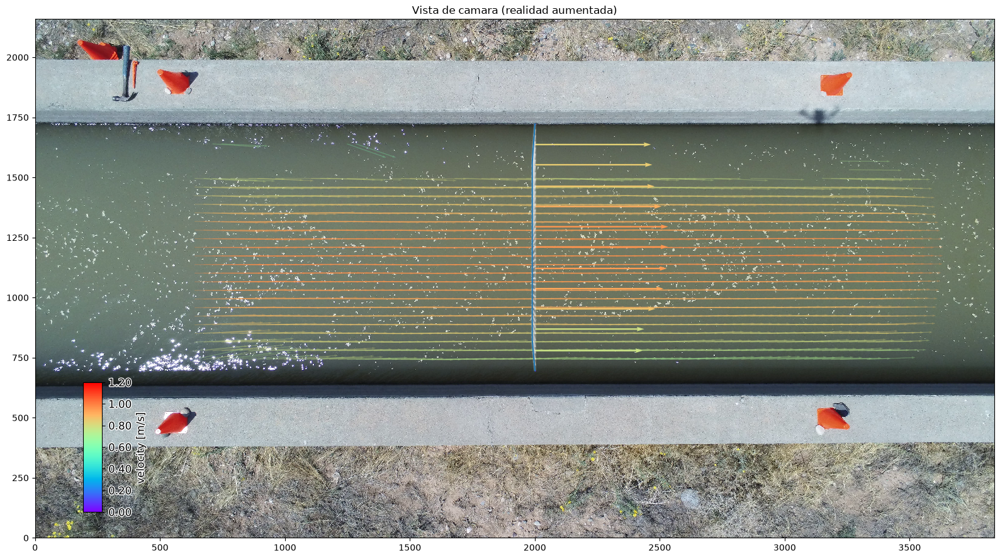

In [ ]:
# Vista de realidad aumentada: todo proyectado de vuelta sobre la imagen del dron.
p = da_rgb[0].frames.plot(mode="camera")
ds_mean_mask.velocimetry.plot(ax=p.axes, mode="camera", alpha=0.3, norm=NORMA_COLOR)
q_transect.sel(quantile=0.5).transect.plot(ax=p.axes, mode="camera", cmap="rainbow",
                                           norm=NORMA_COLOR, width=2, add_colorbar=True)
p.axes.set_title("Vista de camara (realidad aumentada)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig10_vista_camara.png", dpi=110, bbox_inches="tight")
plt.show()

---
### El campo de vectores

LSPIV devuelve **un vector por ventana de interrogacion**, con modulo y direccion propios. Esta es
la diferencia de forma con STIV, que da un solo escalar por linea de busqueda: aqui hay campo 2D, y
por eso la mascara de direccion de la Parte 4b tiene sentido.

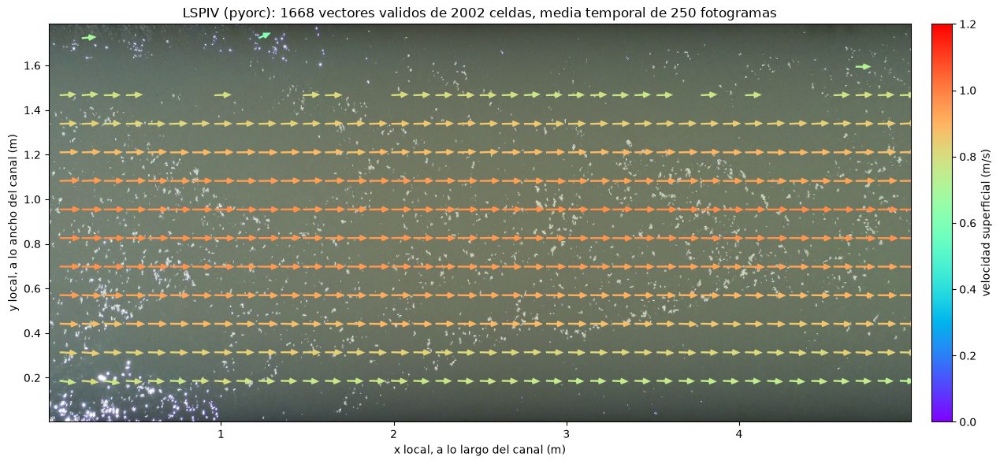

Celdas con vector valido: 1668 de 2002 (83.3 %)
Velocidad media del campo: 0.884 m/s   maxima: 0.992 m/s


In [ ]:
# Campo de vectores del LSPIV sobre el canal reproyectado. Es la salida caracteristica del
# metodo: una flecha por ventana de interrogacion, con direccion propia, sobre la malla de
# 0.004 m/px. Se dibuja la media temporal de los 250 fotogramas ya filtrados, y se pinta una
# de cada dos celdas en cada eje para que las flechas no se solapen.
PASO_FLECHAS = 2
ESCALA_FLECHAS = 8.0     # m/s por metro de flecha dibujado

xg = ds_mean_mask["x"].values
yg = ds_mean_mask["y"].values
X, Y = np.meshgrid(xg, yg)
vx = ds_mean_mask["v_x"].values
vy = ds_mean_mask["v_y"].values
mag = np.hypot(vx, vy)

r = (slice(None, None, PASO_FLECHAS), slice(None, None, PASO_FLECHAS))

p = da_rgb_proj[0].frames.plot(mode="local")
ax = p.axes
ax.figure.set_size_inches(14, 6)
q = ax.quiver(X[r], Y[r], vx[r], vy[r], mag[r],
              cmap="rainbow", norm=NORMA_COLOR,
              angles="xy", scale_units="xy", scale=ESCALA_FLECHAS,
              width=0.0022, headwidth=3.5, headlength=4)
ax.figure.colorbar(q, ax=ax, label="velocidad superficial (m/s)", pad=0.02)

# Las dos lineas de agua, para situar los vectores dentro del canal.
for ym, etq in ((0.0, "muro superior"), (ANCHO_CANAL, "muro inferior")):
    ax.axhline(ym, color="w", ls="--", lw=1.2, alpha=0.8)
ax.set_title(f"LSPIV (pyorc): {int(np.isfinite(mag).sum())} vectores validos de "
             f"{mag.size} celdas, media temporal de {N_FRAMES} fotogramas")
ax.set_xlabel("x local, a lo largo del canal (m)")
ax.set_ylabel("y local, a lo ancho del canal (m)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig11_vectores_canal.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Celdas con vector valido: {int(np.isfinite(mag).sum())} de {mag.size} "
      f"({100 * np.isfinite(mag).mean():.1f} %)")
print(f"Velocidad media del campo: {np.nanmean(mag):.3f} m/s   "
      f"maxima: {np.nanmax(mag):.3f} m/s")


---
## Parte 6 - Recursos consumidos

Resumen de lo que ha costado cada etapa. Las columnas son:

- **segundos**: tiempo de reloj.
- **cpu_s** y **nucleos**: tiempo de CPU sumando todos los nucleos, y el cociente entre ambos. Un
  valor de 1.0 significa un solo hilo saturado; por encima, que la etapa paraleliza.
- **ram_pico_mb**: maximo de memoria residente del proceso durante la etapa, muestreado en un hilo
  aparte. Es el numero que decide si un video mas largo cabe en memoria.
- **ram_neta_mb**: lo que queda ocupado al terminar. Alto no significa fuga, sino que la etapa deja
  datos vivos (un dataset cargado, por ejemplo).

Lo que hay que mirar es el reparto de `pct_tiempo`. Contra lo que sugiere la documentacion de
pyorc, el grueso se va en `get_piv` y no en `to_netcdf` (ver la explicacion de la Parte 4), y el
pico de memoria se alcanza tambien ahi. Son los dos numeros que limitan cuanto se puede subir
`N_FRAMES` en esta maquina.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 8
  cpu_nucleos_logicos: 12
  ram_total_gb: 42.7
  ram_disponible_gb: 22.8

Tiempo total medido: 159.1 s
Pico de memoria del proceso: 13670 MB
Guardado en: salidas\benchmark_recursos.csv



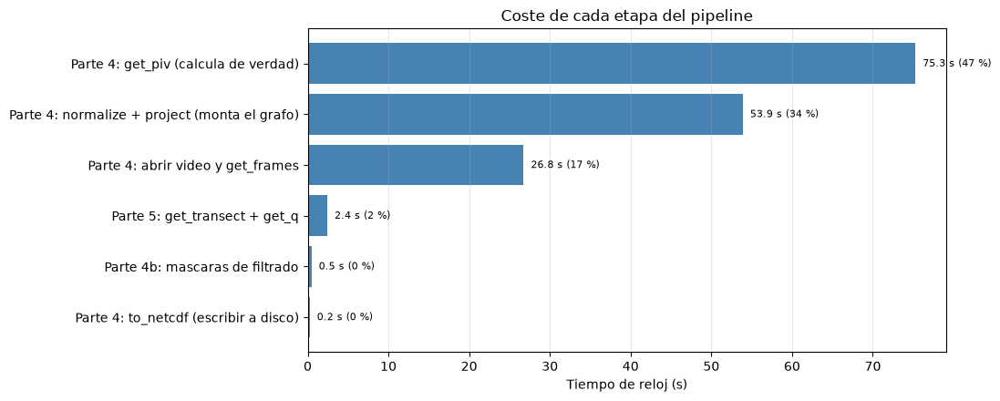

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 4: abrir video y get_frames,26.75,136.91,5.12,1266.3,132.8,250,16.8
1,Parte 4: normalize + project (monta el grafo),53.90,468.30,8.69,7450.0,104.5,250,33.9
2,Parte 4: get_piv (calcula de verdad),75.28,671.36,8.92,13670.3,1137.0,250,47.3
3,Parte 4: to_netcdf (escribir a disco),0.25,0.28,1.12,2094.0,-2.6,250,0.2
4,Parte 4b: mascaras de filtrado,0.47,0.45,0.96,1223.8,16.6,250,0.3
5,Parte 5: get_transect + get_q,2.43,2.34,0.97,1403.8,0.2,250,1.5


In [ ]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()

# Se guarda para poder comparar entre maquinas o entre configuraciones del PIV.
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)

print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")
print(f"Guardado en: {SALIDA_BENCHMARK}\n")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa del pipeline")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig12_recursos.png", dpi=110, bbox_inches="tight")
plt.show()

tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui no se ha usado ni un solo dato de validacion: el caudal de la Parte 5 sale de la
geometria del canal, del video y de los valores por defecto de pyorc. Ahora se abren las dos
referencias que trae el data release del USGS:

1. **El aforo con FlowTracker** (ADV, por vadeo) del mismo dia: caudal total, area, velocidad media
   y la velocidad media en la vertical de cada una de las 13 verticales. Es una medida de campo
   **independiente**, con incertidumbre ISO declarada del 4.2 %.
2. **El LSPIV del propio USGS** (`SMC_PIV_results.mat`, procesado con PIVlab). Ojo: corresponde al
   vuelo **020** y no al **022** que se procesa aqui, volado a otra altura y con otra escala
   (2.112 mm/px). Sirve para contrastar la **forma** del perfil, no para una comparacion punto a
   punto.

**Esta es la ultima parte del notebook. No se vuelve atras a ajustar nada.**

In [ ]:
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Es la primera vez que aparecen en el notebook: hasta aqui no se ha
#  usado ni uno solo de ellos, y despues de esta parte no se ajusta nada.
#  Aforo con FlowTracker (ADV, por vadeo) del 2020-08-17 11:17. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
Q_AFORO = 1.4362              # m3/s, caudal total medido
AREA_AFORO = 1.799            # m2, area de la seccion segun el convenio mid-section
V_MEDIA_AFORO = 0.7985        # m/s, velocidad media en la seccion
V_ADV = np.array([0.0, 0.6298, 0.7973, 0.8132, 0.8121, 0.8220, 0.8518,   # m/s, media en la
                  0.8508, 0.8458, 0.8094, 0.8146, 0.7365, 0.0])         # vertical, una por vertical
# ---------------------------------------------------------------------------------------

error_rel = 100 * (Q_PYORC / Q_AFORO - 1)

print("=" * 66)
print("CAUDAL")
print("=" * 66)
print(f"  LSPIV con pyorc (este notebook) : {Q_PYORC:.4f} m3/s")
print(f"  Aforo FlowTracker (ADV)         : {Q_AFORO:.4f} m3/s   (incertidumbre ISO 4.2 %)")
print(f"  Diferencia                      : {error_rel:+.1f} %")
print()
print(f"  Banda de cuantiles del PIV      : P5 = {q_05:.4f}  P95 = {q_95:.4f} m3/s")
print(f"                                    ({100 * (q_05 / Q_AFORO - 1):+.1f} % .. "
      f"{100 * (q_95 / Q_AFORO - 1):+.1f} % frente al aforo)")
print()
print(f"  Area de la seccion   pyorc {AREA_SECCION:.4f} m2  |  aforo {AREA_AFORO:.4f} m2")
print(f"  Velocidad media      pyorc {Q_PYORC / AREA_SECCION:.4f} m/s |  aforo {V_MEDIA_AFORO:.4f} m/s")
print("=" * 66)

print("\nCaudal por cuantil frente al aforo:")
for qt in caudal["quantile"].values:
    val = float(caudal.sel(quantile=qt))
    print(f"  cuantil {qt:.2f}: {val:8.4f} m3/s   {100 * (val / Q_AFORO - 1):+6.1f} %")

v_media_vertical = v_eff * V_CORR
comparacion = pd.DataFrame({
    "vertical": np.arange(N_VERTICALES),
    "s_m": s_transecto,
    "v_sup_pyorc": v_eff,
    "v_media_pyorc": v_media_vertical,
    "v_media_ADV": V_ADV,
    "dif_pct": np.where(V_ADV > 0,
                        100 * (v_media_vertical / np.where(V_ADV > 0, V_ADV, 1) - 1), np.nan),
    "origen": perfil["origen"],
})
print("\nVertical por vertical:")
print(comparacion.to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

CAUDAL
  LSPIV con pyorc (este notebook) : 1.4565 m3/s
  Aforo FlowTracker (ADV)         : 1.4362 m3/s   (incertidumbre ISO 4.2 %)
  Diferencia                      : +1.4 %

  Banda de cuantiles del PIV      : P5 = 1.3532  P95 = 1.5754 m3/s
                                    (-5.8 % .. +9.7 % frente al aforo)

  Area de la seccion   pyorc 1.8026 m2  |  aforo 1.7990 m2
  Velocidad media      pyorc 0.8080 m/s |  aforo 0.7985 m/s

Caudal por cuantil frente al aforo:
  cuantil 0.05:   1.3532 m3/s     -5.8 %
  cuantil 0.25:   1.4114 m3/s     -1.7 %
  cuantil 0.50:   1.4565 m3/s     +1.4 %
  cuantil 0.75:   1.5069 m3/s     +4.9 %
  cuantil 0.95:   1.5754 m3/s     +9.7 %

Vertical por vertical:
 vertical      s_m  v_sup_pyorc  v_media_pyorc  v_media_ADV  dif_pct                      origen
        0   0.0000       0.0000         0.0000       0.0000      NaN contorno (v=0 por convenio)
        1   0.1500       0.8343         0.7676       0.6298  21.8788          relleno log_interp
        2 

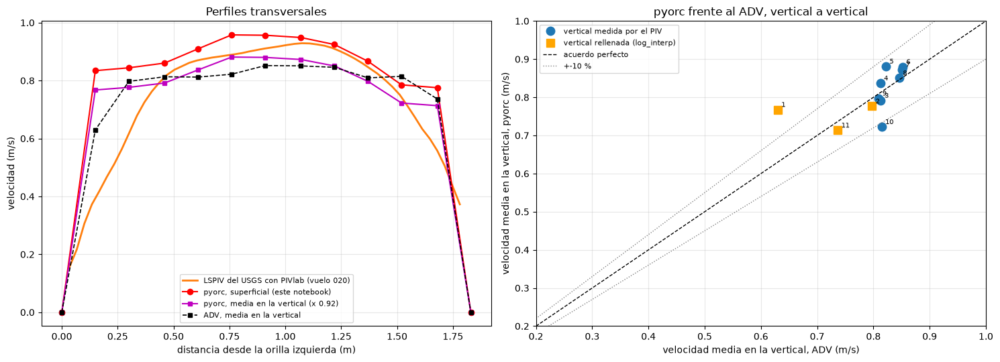

Sobre las 8 verticales medidas (se excluyen las 3 rellenadas):
  Sesgo medio frente al ADV: +0.0017 m/s (+0.2 %)
  RMSE:                      0.0426 m/s

Cociente implicito entre lo que midio el ADV y la velocidad superficial de este LSPIV:
  v_corr implicito = 0.918  (el notebook uso 0.92)
Es un diagnostico, no una correccion: no se vuelve atras a cambiar v_corr.


In [ ]:
from scipy.io import loadmat

mat = loadmat(str(ARCHIVO_PIV_USGS))
# u_mean y v_mean estan en m/s; y_ground es la coordenada transversal en metros. Se promedia
# a lo largo del canal para tener un solo perfil transversal.
perfil_usgs = np.hypot(mat["u_mean"], mat["v_mean"]).mean(axis=1)
y_usgs = mat["y_ground"][:, 0]
orden_y = np.argsort(y_usgs)   # y_ground viene en orden descendente

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ax.plot(y_usgs[orden_y], perfil_usgs[orden_y], "-", color="tab:orange", lw=2,
        label="LSPIV del USGS con PIVlab (vuelo 020)")
ax.plot(s_transecto, v_eff, "r-o", ms=6, label="pyorc, superficial (este notebook)")
ax.plot(s_transecto, v_media_vertical, "m-s", ms=5,
        label=f"pyorc, media en la vertical (x {V_CORR})")
ax.plot(s_transecto, V_ADV, "ks--", ms=5, lw=1.2, label="ADV, media en la vertical")
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad (m/s)")
ax.set_title("Perfiles transversales")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
interior = ~ES_CONTORNO              # las dos verticales del borde son v=0 por convenio
med = interior & medida
rel = interior & ~medida
ax.plot(V_ADV[med], v_media_vertical[med], "o", ms=9, color="tab:blue",
        label="vertical medida por el PIV")
ax.plot(V_ADV[rel], v_media_vertical[rel], "s", ms=9, color="orange",
        label="vertical rellenada (log_interp)")
lim = [0.2, 1.0]
ax.plot(lim, lim, "k--", lw=1, label="acuerdo perfecto")
ax.plot(lim, [1.1 * v for v in lim], ":", color="gray", lw=1, label="+-10 %")
ax.plot(lim, [0.9 * v for v in lim], ":", color="gray", lw=1)
for i in np.where(interior)[0]:
    ax.annotate(str(i), (V_ADV[i], v_media_vertical[i]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("velocidad media en la vertical, ADV (m/s)")
ax.set_ylabel("velocidad media en la vertical, pyorc (m/s)")
ax.set_title("pyorc frente al ADV, vertical a vertical")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.grid(alpha=0.3); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig13_comparacion.png", dpi=110, bbox_inches="tight")
plt.show()

# Las estadisticas se calculan solo sobre las verticales que el PIV midio de verdad. Meter las
# rellenadas mediria el relleno, no el metodo.
sesgo = float(np.mean(v_media_vertical[med] - V_ADV[med]))
rmse = float(np.sqrt(np.mean((v_media_vertical[med] - V_ADV[med]) ** 2)))
v_corr_implicito = float(V_ADV[med].mean() / v_eff[med].mean())

print(f"Sobre las {int(med.sum())} verticales medidas (se excluyen las {int(rel.sum())} rellenadas):")
print(f"  Sesgo medio frente al ADV: {sesgo:+.4f} m/s ({100 * sesgo / V_ADV[med].mean():+.1f} %)")
print(f"  RMSE:                      {rmse:.4f} m/s")
print(f"\nCociente implicito entre lo que midio el ADV y la velocidad superficial de este LSPIV:")
print(f"  v_corr implicito = {v_corr_implicito:.3f}  (el notebook uso {V_CORR})")
print("Es un diagnostico, no una correccion: no se vuelve atras a cambiar v_corr.")

In [ ]:
# Resumen final, y donde queda cada fuente de incertidumbre.
resumen = pd.DataFrame([
    dict(concepto="Caudal LSPIV pyorc (este notebook)", valor=Q_PYORC, unidad="m3/s"),
    dict(concepto="Caudal aforo FlowTracker", valor=Q_AFORO, unidad="m3/s"),
    dict(concepto="Diferencia", valor=error_rel, unidad="%"),
    dict(concepto="Cuantil 0.05 del PIV", valor=q_05, unidad="m3/s"),
    dict(concepto="Cuantil 0.95 del PIV", valor=q_95, unidad="m3/s"),
    dict(concepto="Incertidumbre declarada del aforo", valor=4.2, unidad="%"),
    dict(concepto="Incertidumbre por la escala (5 px)", valor=100 * 5 / ANCHO_CANAL_PX, unidad="%"),
    dict(concepto="v_corr usado", valor=V_CORR, unidad="-"),
    dict(concepto="v_corr implicito segun el ADV (verticales medidas)", valor=v_corr_implicito,
         unidad="-"),
    dict(concepto="Verticales medidas por el PIV", valor=int(med.sum()), unidad="de 11"),
    dict(concepto="Verticales rellenadas por log_interp", valor=int(rel.sum()), unidad="de 11"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
print(resumen.to_string(index=False, float_format=lambda x: f"{x:9.4f}"))
print(f"\nGuardado en: {SALIDA_RESUMEN}")

                                          concepto     valor unidad
                Caudal LSPIV pyorc (este notebook)    1.4565   m3/s
                          Caudal aforo FlowTracker    1.4362   m3/s
                                        Diferencia    1.4104      %
                              Cuantil 0.05 del PIV    1.3532   m3/s
                              Cuantil 0.95 del PIV    1.5754   m3/s
                 Incertidumbre declarada del aforo    4.2000      %
                Incertidumbre por la escala (5 px)    0.4878      %
                                      v_corr usado    0.9200      -
v_corr implicito segun el ADV (verticales medidas)    0.9182      -
                     Verticales medidas por el PIV    8.0000  de 11
              Verticales rellenadas por log_interp    3.0000  de 11

Guardado en: salidas\caudal_resumen.csv


---
## Archivos generados

Todo queda en `salidas/`, sin tocar nada de la carpeta `../USGS/`.

In [ ]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    print(f"  {archivo.name:<36} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                      0.5 KiB
  cam_config_smc.json                         1.7 KiB
  caudal_resumen.csv                          0.5 KiB
  config_pyorc.json                           0.7 KiB
  fig10_vista_camara.png                   2238.6 KiB
  fig11_vectores_canal.png                  879.3 KiB
  fig12_recursos.png                         35.9 KiB
  fig13_comparacion.png                     128.9 KiB
  fig1_fotograma.png                        960.7 KiB
  fig2_puntos_control.png                   405.7 KiB
  fig3_area_interes.png                     953.6 KiB
  fig4_reproyeccion.png                     920.5 KiB
  fig5_velocidades_sin_filtrar.png         1299.8 KiB
  fig6_velocidades_filtradas.png           1112.0 KiB
  fig7_seccion.png                           49.9 KiB
  fig8_perfil_transecto.png                  96.8 KiB
  fig9_mapa_transecto.png                  1029.4 KiB
  perfil_transecto.csv                        1.2 KiB
  piv

---
## Lectura del resultado

El notebook no vuelve atras a partir de aqui. Lo que hay que leer de la comparacion:

**Lo que el metodo hace bien.** El campo de velocidades sale del video sin ninguna informacion
hidraulica: la forma del perfil transversal, con el maximo en el centro y la caida hacia los dos
muros, no se ha impuesto en ningun sitio. Coincide en forma con el LSPIV que publico el propio USGS
sobre otro vuelo y con otro software, y con lo que midio el ADV vertical a vertical.

**Donde se va el error.** Por orden de peso:

1. **Las verticales pegadas a los muros son relleno, no medida.** Las ventanas de interrogacion que
   tocan el hormigon pierden correlacion y se quedan sin dato valido, asi que `log_interp` las
   reconstruye. En la figura 12, esas verticales son los cuadrados naranjas, y se separan de la
   diagonal mucho mas que ninguna de las medidas. Es la debilidad conocida del caso, y no es
   exclusiva de pyorc: el perfil que publico el USGS con PIVlab cae igual junto a los muros, tanto
   que integrarlo tal cual daria un caudal aproximadamente un 15 % por debajo del aforo.
2. **`v_corr`.** Se uso 0.92, el mismo que el notebook de STIV, fijado antes de mirar nada. El propio
   ADV permite estimarlo a posteriori en las verticales que el PIV si mide, y el numero aparece en
   la Parte 7. **Ese valor no se ha usado para corregir el resultado**, y no debe usarse: si se
   ajusta `v_corr` hasta acertar, deja de haber validacion y solo queda una calibracion.
3. **La escala.** Todo el caudal es proporcional a ella. La linea de agua del muro superior es un
   escalon limpio, pero la del inferior es una rampa en sombra de unos 85 px: es la mayor
   incertidumbre geometrica del caso, y la figura 2 esta puesta precisamente para que se pueda
   discutir con el perfil de brillo delante.
4. **El convenio de area.** El caudal replica la seccion mid-section del CSV (1.803 m2); la caja
   fisica del canal es un 9 % mayor. No es un error del metodo sino la convencion del dato.

## Limitaciones conocidas

1. **El sesgo junto a los muros.** Varias verticales del transecto son relleno logaritmico y no
   medida. Es la mayor fuente de incertidumbre de este caso.
2. **La escala cuelga de dos filas de pixeles.** Diez pixeles de error son un 1 % en el caudal, y
   la fila del muro inferior no se lee sobre un escalon limpio sino sobre una rampa en sombra.
3. **`v_corr` no es medible en la imagen.** Ninguna tecnica de velocimetria superficial puede
   resolverlo sin informacion de la vertical.
4. **El convenio de area.** El caudal calculado replica la geometria mid-section del CSV; el caudal
   fisico real del canal es un 9 % mayor.
5. **Sin correccion de distorsion de lente.** El data release no publica el modelo de la camara.
   Por eso el area de interes se limita a las columnas 600-3400 y no a la imagen entera.
6. **La referencia del USGS es de otro clip.** `SMC_PIV_results.mat` corresponde al vuelo 020, no
   al 022 que se procesa aqui, asi que sirve para contrastar la forma del perfil pero no para una
   comparacion punto a punto.
7. **La estabilizacion es un paso previo y no se revalida aqui.** Si se cambia el poligono o el
   rango de fotogramas hay que volver a ejecutar `estabilizar_video.py`; el notebook no detecta que
   el video de `entradas/` se haya quedado desfasado respecto a lo que se pretende procesar.

## Como llevar este notebook a otro caso

Cada constante ajustable esta al principio del bloque donde se usa, marcada `>>> AJUSTABLE <<<`.
Este es el indice completo:

| Constante | Donde | Como se obtiene |
|---|---|---|
| `ARCHIVO_VIDEO`, `ARCHIVO_SECCION` | Parte 0 | rutas; el CSV lleva `Progresiva` y `Prof` |
| `COLUMNA_GCP`, `FILA_AGUA_SUP`, `FILA_AGUA_INF` | Parte 2 | leyendo el primer fotograma, o con `pixel_locator.py` |
| `ANCHO_CANAL` | Parte 2 | una distancia real conocida entre esas dos filas *(del dataset)* |
| `RESOLUCION`, `VENTANA_PIV` | Parte 3 | por geometria: ancho del cauce y desplazamiento por fotograma |
| `COLUMNA_INI`, `COLUMNA_FIN`, `ESQUINAS_AOI` | Parte 3 | tramo util de la imagen, por dentro de las lineas de agua |
| `N_FRAMES` | Parte 4 | cuanto video procesar |
| `PROFUNDIDAD` | Parte 5 | geometria de la seccion *(del dataset)*; la progresiva sale del CSV |
| `V_CORR` | Parte 5 | convenio hidrometrico; aqui 0.92, el mismo que el caso de STIV |
| `Q_AFORO`, `V_ADV`, ... | Parte 7 | datos de validacion *(del dataset)*; no se tocan antes |

Las mascaras de la Parte 4b van con sus parametros por defecto y no suele hacer falta tocarlas.

## Equivalencia con los otros notebooks del workspace

Mismo video y misma referencia que el caso de STIV, con otro algoritmo; y mismo pipeline de pyorc
que el caso de Ngwerere.

| Este notebook (LSPIV con pyorc) | `analisis_USGS_SMC_stiv/SMC_STIV_pipeline.ipynb` (STIV) | `analisis_ngwerere` |
|---|---|---|
| (previo) `estabilizar_video.py`, funciones de pyorc | (previo) `estabilizar_stiv.py`, OpenCV puro | (no hace falta: camara fija) |
| Parte 0: rutas | Parte 0: rutas | Parte 0 |
| Parte 1: `pyorc.Video` | Parte 1: `cv2.VideoCapture` | Parte 1 |
| Parte 2: 2 GCPs, modo nadir | Parte 2: escala por la lamina de agua | Parte 2: 4 GCPs RTK |
| Parte 3: `CameraConfig` + AOI + `project` | Parte 3: lineas de busqueda y STI | Parte 3 |
| Parte 4: `get_piv` (correlacion cruzada 2D) | Parte 4: tensor de estructura por bloques | Parte 4 |
| Parte 4b: mascaras `velocimetry.mask.*` | Parte 4b: coherencia + relleno por interpolacion | Parte 4b |
| Parte 5: `get_transect` + `get_q` + `get_river_flow` | Parte 5: trapecios sobre las verticales | Parte 5 |
| Parte 6: recursos, con el mismo `benchmark.py` | Parte 6: recursos | (no la lleva) |
| Parte 7: comparacion, y fin | Parte 7: comparacion, y fin | (compara contra otro resultado de pyorc) |